PCA（主成分分析）を実行し、その計算結果を後の解析や可視化で利用するために保存しています

pcaDF_axes.csv: 各主成分（PC）に対するタンパク質の寄与度（ローディング）を示す主成分軸データです

pca_varDF.csv: 各主成分がデータ全体のばらつきをどの程度説明しているかを示す寄与率データです

pca_projDF.csv: 各サンプルを主成分空間に投影した際の座標である主成分スコアデータです

DataForRegression.csv: 回帰分析用に主成分スコアを整理したデータセットです


# Install library

In [1]:
#Initial setup
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

In [2]:
import pandas as pd
import os

In [3]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from decimal import Decimal, ROUND_HALF_UP
import matplotlib.pyplot as plt
import seaborn as sns

# Import Data

In [4]:
print(os.getcwd())

/home/jovyan/PancreasProject/Aichi_Proteomics


## Omics data

In [5]:
fileDir = "./Data/"
fileName = "pro_data.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

pro_data = temp

,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PE_R478_001,-0.011714,-0.032043,-0.250458,-0.391125,-0.252621,0.150167,-0.047767,-0.316298,-0.044654,0.516400,...,0.734304,0.110696,0.058819,-0.250565,-0.145040,-0.262231,-0.306965,-0.328111,0.216998,-0.101624
PE_R478_002,0.006932,-0.102609,0.650528,1.724016,0.550598,2.128050,-0.040240,1.335081,0.269637,-0.182468,...,3.043780,0.944960,-0.074905,-0.028470,-0.112292,0.009771,0.605862,1.732763,0.050603,-0.070623
PE_R478_003,-0.060158,0.139603,-0.391076,0.827442,0.564473,0.000000,2.602543,0.168998,-0.149231,0.027239,...,-0.175562,0.927932,0.247506,1.032951,-0.320810,0.012949,0.187431,-0.014972,-0.272747,0.060313
PE_R478_004,0.078249,-0.056538,0.070462,-0.096654,-0.382649,0.026322,0.003985,0.493930,-0.002798,-0.114333,...,-0.603477,-0.421595,0.008789,-0.258851,1.877652,0.111118,0.459926,0.325601,3.782591,-0.063099
PE_R478_005,0.023991,-0.016920,0.378868,0.522751,2.066188,1.183532,0.329253,1.291015,1.488711,1.123200,...,2.440574,0.711782,0.082763,1.664001,1.675150,0.773179,0.788874,0.492789,0.191108,0.228033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,0.099132,0.012226,2.090906,0.937016,0.432914,0.422205,-0.034455,0.301893,-0.417816,0.567447,...,-0.318979,0.567542,-0.176940,-1.468123,0.858104,0.097731,-0.573343,-0.164230,0.004873,-0.195060
PE_R478_397,0.034352,-0.037069,0.652913,-0.084482,0.471556,0.067670,0.048786,1.311366,0.047220,-0.000537,...,0.953380,2.234465,0.233921,-0.020321,3.746860,0.025703,0.553025,0.145132,0.019710,2.857327
PE_R478_398,0.066884,0.005657,0.025657,-0.369096,-0.940943,-0.833491,-0.035938,-0.282643,0.902980,-0.354449,...,0.373973,-0.330692,0.003094,0.760417,-0.094866,-0.042590,0.295296,0.252283,-0.597332,0.102647
PE_R478_399,0.020281,-0.033391,0.115515,0.252649,0.799482,-0.555303,-0.095176,0.147232,-0.232622,0.275772,...,-0.294149,2.978748,-0.111313,-0.910355,0.684876,-0.089939,-0.454858,-0.286652,-0.528971,-0.131158


## Sample data

In [6]:
fileDir = "./Data/"
fileName = "pro_sample.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

pro_sample = temp

,progress,sex,fvage,CaCo_Status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R
PE_R478_001,0,1,58,0,NaN,NaN,2,8,1,25,20,0,4.100,134.0
PE_R478_002,0,1,62,0,NaN,NaN,2,10,1,33,23,0,1.999,5500.0
PE_R478_003,0,1,68,0,NaN,NaN,1,24,3,0,22,0,2.700,259.0
PE_R478_004,0,2,70,0,NaN,NaN,3,0,3,0,26,0,3.800,208.0
PE_R478_005,440,1,59,1,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,410,1,63,1,C250,84533.0,1,27,3,0,26,1,1.999,263.0
PE_R478_397,410,2,64,1,C250,85003.0,3,0,1,12,22,0,1.999,257.0
PE_R478_398,0,1,38,0,NaN,NaN,2,13,1,4,29,0,2.100,257.0
PE_R478_399,410,2,47,1,C250,85003.0,3,0,1,2,21,0,16.900,216.0


# PCA

## Standardization

In [7]:
#Z-score transformation
tempDF = pro_data.copy()
print('Before:')
display(tempDF.iloc[:, :15].describe())

tempDF1 = pro_data.copy()
scaler = StandardScaler(copy=True, with_mean=True, with_std=True)
tempA = scaler.fit_transform(tempDF1)#axis: column
tempDF = pd.DataFrame(data=tempA, index=tempDF1.index, columns=tempDF1.columns)

print('After:')
display(tempDF)
display(tempDF.iloc[:, :15].describe())

pro_data_z = tempDF 

Before:


,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,OID50012,OID50013,OID50014,OID50017,OID50018
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,-0.002959,0.015291,0.044661,0.336845,0.106689,0.017878,0.063028,0.013972,0.131581,0.033301,0.269420,0.265993,0.338463,0.099477,0.263182
std,0.066177,0.087934,0.312329,1.175544,0.698146,0.614017,0.330080,0.544660,0.572410,0.421443,0.818394,0.971984,1.484944,0.742275,1.600096
min,-0.221682,-0.158885,-0.692585,-1.351627,-1.662149,-1.620190,-0.380384,-2.121668,-0.733173,-1.044924,-0.676899,-1.438927,-1.452573,-1.583654,-2.978228
25%,-0.041282,-0.038963,-0.121814,-0.276956,-0.380736,-0.362140,-0.071999,-0.301486,-0.193354,-0.181774,-0.176691,-0.338836,-0.573816,-0.281575,-0.953322
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.039444,0.049421,0.152742,0.497758,0.471577,0.337887,0.097237,0.326000,0.277358,0.203204,0.325661,0.591441,0.842479,0.325019,1.129120
max,0.203957,0.702355,2.877360,8.659297,3.153816,2.627490,3.912854,2.898588,3.707043,3.688811,4.352708,5.260313,10.619192,5.777851,7.035730


After:


,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PE_R478_001,-0.132465,-0.538965,-0.946087,-0.620042,-0.515311,0.215720,-0.336085,-0.607141,-0.308269,1.147738,...,0.991835,-0.146533,0.138862,-0.370328,-0.394409,-1.094301,-0.545054,-0.642443,-0.059930,-0.443364
PE_R478_002,0.149648,-1.342459,1.942274,1.181510,0.636641,3.440991,-0.313253,2.428617,0.241487,-0.512623,...,4.324127,0.591903,-0.332623,-0.102273,-0.358944,-0.188166,0.680855,2.283186,-0.234401,-0.378734
PE_R478_003,-0.865430,1.415468,-1.396876,0.417861,0.656539,-0.029152,7.703317,0.284987,-0.491196,-0.014402,...,-0.320990,0.576831,0.804139,1.178798,-0.584756,-0.177579,0.118910,-0.197909,-0.573444,-0.105761
PE_R478_004,1.228678,-0.817873,0.082712,-0.369229,-0.701792,0.013769,-0.179100,0.882315,-0.235054,-0.350748,...,-0.938420,-0.617682,-0.037532,-0.380329,1.796045,0.149458,0.484866,0.285570,3.678711,-0.363048
PE_R478_005,0.407745,-0.366766,1.071392,0.158344,2.810250,1.900796,0.807562,2.347610,2.373889,2.589366,...,3.453774,0.385509,0.223285,1.940439,1.576748,2.355026,0.926638,0.522911,-0.087076,0.243898
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,1.544637,-0.034902,6.559809,0.511190,0.467862,0.659325,-0.295705,0.529290,-0.961004,1.269017,...,-0.527924,0.257837,-0.692380,-1.839849,0.691937,0.104862,-0.902795,-0.409796,-0.282350,-0.638158
PE_R478_397,0.564509,-0.596189,1.949920,-0.358861,0.523281,0.081195,-0.043202,2.385021,-0.147564,-0.080393,...,1.307935,1.733288,0.756241,-0.092438,3.820285,-0.135088,0.609897,0.029376,-0.266793,5.725392
PE_R478_398,1.056722,-0.109692,-0.060925,-0.601279,-1.502479,-1.388300,-0.300203,-0.545272,1.349330,-0.921212,...,0.471921,-0.537221,-0.057613,0.849866,-0.340072,-0.362598,0.263771,0.181488,-0.913782,-0.017504
PE_R478_399,0.351616,-0.554306,0.227142,-0.071713,0.993582,-0.934668,-0.479894,0.244974,-0.637064,0.576059,...,-0.492096,2.392078,-0.460990,-1.166656,0.504341,-0.520334,-0.743672,-0.583587,-0.842103,-0.504936


,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,OID50012,OID50013,OID50014,OID50017,OID50018
count,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02
mean,3.793727e-17,-1.115802e-17,4.463208e-18,-1.785283e-17,2.677925e-17,1.785283e-17,4.463208e-18,-2.677925e-17,-5.355850e-17,-1.394753e-17,-1.785283e-17,-3.570567e-17,-8.926416e-18,1.785283e-17,-1.785283e-17
std,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00
min,-3.309313e+00,-1.983242e+00,-2.363447e+00,-1.438140e+00,-2.536810e+00,-2.671145e+00,-1.345038e+00,-3.925984e+00,-1.512626e+00,-2.561632e+00,-1.157766e+00,-1.756269e+00,-1.207649e+00,-2.270385e+00,-2.028309e+00
25%,-5.798382e-01,-6.177562e-01,-5.336815e-01,-5.227990e-01,-6.990479e-01,-6.196834e-01,-4.095893e-01,-5.799119e-01,-5.683754e-01,-5.109734e-01,-5.457906e-01,-6.230457e-01,-6.151257e-01,-5.140028e-01,-7.612262e-01
50%,4.476269e-02,-1.741073e-01,-1.431737e-01,-2.869045e-01,-1.530092e-01,-2.915243e-02,-1.911894e-01,-2.568544e-02,-2.301610e-01,-7.911709e-02,-3.296199e-01,-2.740044e-01,-2.282169e-01,-1.341848e-01,-1.646858e-01
75%,6.415506e-01,3.886205e-01,3.464818e-01,1.370564e-01,5.233114e-01,5.218292e-01,1.037673e-01,5.736051e-01,2.549929e-01,4.036530e-01,6.880817e-02,3.352501e-01,3.398447e-01,3.042352e-01,5.418596e-01
max,3.130654e+00,7.823202e+00,9.081005e+00,7.088570e+00,4.370092e+00,4.255413e+00,1.167799e+01,5.302838e+00,6.254193e+00,8.684709e+00,4.995668e+00,5.144739e+00,6.932024e+00,7.659593e+00,4.237915e+00


## Fit a PCA model

In [8]:
tempDF1 = pro_data_z.select_dtypes(include=np.number)#Take the continous variables
tempDF2 = pro_data_z.select_dtypes(exclude=np.number)#Take the categorical variables
# nPCs = len(tempDF1.columns)#Calculate the same number of PCs with features
nPCs = min(tempDF1.shape[0], tempDF1.shape[1])

#Fit a PCA model
model = PCA(n_components=nPCs, svd_solver='randomized', iterated_power='auto', random_state=123)
model.fit(tempDF1)

cumulative_variance = np.cumsum(model.explained_variance_ratio_)
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(n_components_95)

259


Percentage of variance explained by each component:


PC1      19.908293
PC2       6.953059
PC3       3.772961
PC4       3.357069
PC5       2.371750
           ...    
PC255     0.062597
PC256     0.060785
PC257     0.060648
PC258     0.060091
PC259     0.059798
Name: ExplainedVariance, Length: 259, dtype: float64

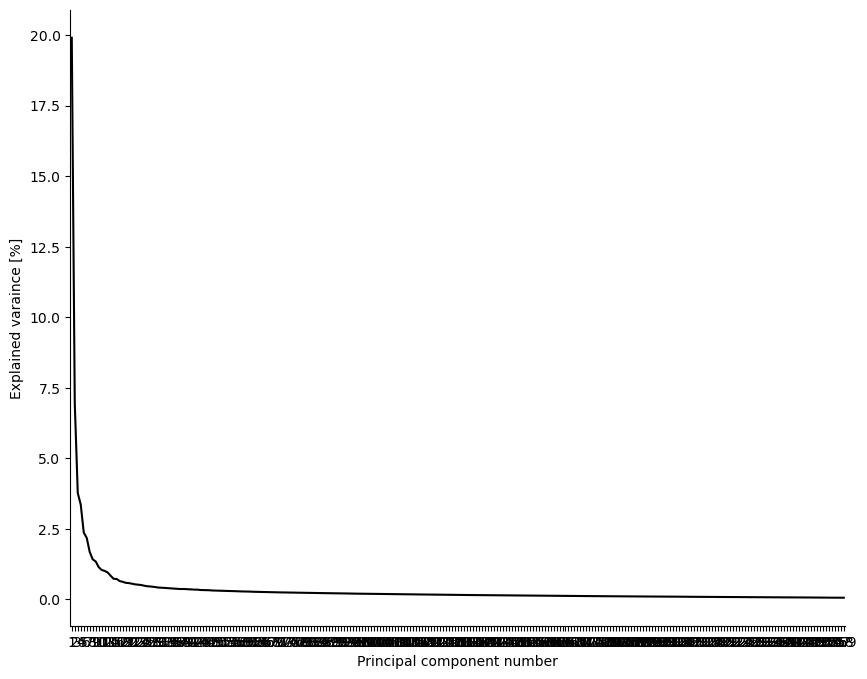

Percentage of variance


,PCnumber,ExplainedVariance,PClabel
Axis,,,
PC1,1,19.908293,PC1
PC2,2,6.953059,PC2
PC3,3,3.772961,PC3
PC4,4,3.357069,PC4
PC5,5,2.371750,PC5
...,...,...,...
PC255,255,0.062597,PC255
PC256,256,0.060785,PC256
PC257,257,0.060648,PC257


Principal axes:


,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PC1,0.018141,-0.004737,0.021761,0.006063,0.041839,0.030468,0.006441,0.043154,0.017218,0.015853,...,0.039344,0.018985,0.012664,0.035853,0.031691,0.023250,0.040980,0.034978,0.009618,0.027507
PC2,-0.011992,0.010740,-0.003306,-0.009857,-0.043476,-0.009187,0.001369,-0.039104,-0.010706,-0.004135,...,-0.028666,-0.000839,-0.009036,-0.065866,0.020575,0.016238,-0.041701,-0.029594,-0.004091,-0.026546
PC3,-0.001035,-0.015287,-0.005925,0.023402,0.071158,0.019409,-0.004748,0.015814,0.012418,0.016363,...,-0.017275,0.003634,-0.019394,-0.077463,-0.005245,0.006774,0.016748,-0.014603,0.011661,-0.029670
PC4,-0.014467,0.011010,-0.004627,-0.013568,-0.027955,-0.014996,-0.020517,-0.004934,-0.008837,-0.003717,...,0.011654,0.005623,-0.019869,-0.014138,0.092737,0.004326,0.001004,-0.003687,-0.014803,0.006287
PC5,-0.057522,-0.016070,-0.049044,-0.018675,-0.022332,-0.045029,-0.021405,-0.017342,-0.021832,-0.000922,...,0.011160,-0.019369,-0.015369,0.028363,-0.029990,-0.036025,-0.013407,-0.005913,-0.030760,-0.023038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC255,-0.046008,0.026657,0.043553,-0.095817,-0.032160,-0.011763,0.028164,0.013966,-0.010409,0.022412,...,0.015217,-0.008828,-0.031507,-0.005965,0.048988,-0.011612,0.022444,-0.035590,0.003275,0.030763
PC256,-0.021451,-0.057636,0.002539,0.006031,-0.019448,-0.020783,0.019314,-0.030096,-0.042540,0.052954,...,0.006478,-0.006066,-0.005593,0.001059,-0.012795,-0.028930,-0.031454,0.006893,-0.020728,0.029081
PC257,-0.020061,0.018352,0.063575,-0.027166,0.015082,-0.024189,-0.007664,0.051994,-0.043859,-0.033885,...,-0.046666,0.037734,0.020240,0.009389,-0.019547,-0.022127,0.032089,-0.043474,0.005664,0.005803
PC258,0.015700,0.015389,0.028041,0.055394,-0.010367,0.038182,0.039445,0.009034,0.043802,0.022032,...,-0.016742,-0.002900,0.010847,-0.014274,0.034153,0.038502,-0.017810,-0.013876,0.007142,-0.027913


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
count,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000,1036.000000
mean,0.026384,0.004186,-0.005634,-0.006120,-0.007246,-0.000157,-0.001552,-0.000870,0.000160,0.000912,0.000093,-0.001907,-0.001386,-0.001773,0.001109
std,0.016414,0.030800,0.030568,0.030474,0.030226,0.031083,0.031045,0.031071,0.031083,0.031070,0.031083,0.031025,0.031053,0.031033,0.031064
min,-0.029150,-0.070624,-0.112158,-0.089681,-0.104994,-0.073874,-0.104177,-0.109692,-0.102653,-0.092301,-0.109397,-0.148297,-0.087893,-0.133698,-0.113983
25%,0.013550,-0.016499,-0.018430,-0.025394,-0.024674,-0.019950,-0.019886,-0.021206,-0.019802,-0.020142,-0.020026,-0.019189,-0.020372,-0.020365,-0.020153
50%,0.026426,0.006538,-0.005229,-0.010379,-0.007603,-0.005358,-0.000939,-0.001554,0.001111,-0.000394,-0.001674,-0.000244,-0.004144,-0.001000,-0.001195
75%,0.039364,0.028636,0.009513,0.006563,0.012173,0.013135,0.016458,0.016666,0.019810,0.021447,0.019526,0.015825,0.015736,0.016814,0.019851
max,0.061442,0.072387,0.088845,0.103831,0.080235,0.152999,0.091711,0.119657,0.096706,0.116065,0.134915,0.145215,0.116061,0.115533,0.125603


Projections:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC250,PC251,PC252,PC253,PC254,PC255,PC256,PC257,PC258,PC259
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
count,3.980000e+02,398.000000,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02
mean,4.284680e-16,0.000000,-5.355850e-17,2.142340e-16,-3.570567e-17,7.141133e-17,-3.570567e-17,2.677925e-17,5.355850e-17,4.463208e-17,-1.071170e-16,-3.570567e-17,-3.570567e-17,-2.677925e-17,-5.355850e-17
std,1.437948e+01,8.497949,6.259899e+00,5.904815e+00,4.963187e+00,4.757023e+00,4.177342e+00,3.839139e+00,3.735517e+00,3.447219e+00,3.290535e+00,3.240408e+00,3.148213e+00,2.950319e+00,2.752280e+00
min,-2.711635e+01,-26.296581,-1.668219e+01,-1.698651e+01,-1.455002e+01,-1.405542e+01,-1.096862e+01,-1.130787e+01,-1.186045e+01,-8.757062e+00,-1.019624e+01,-1.006018e+01,-1.141658e+01,-9.669755e+00,-7.867757e+00
25%,-9.358061e+00,-5.267991,-4.268379e+00,-3.316688e+00,-3.367194e+00,-2.697410e+00,-2.966586e+00,-2.470633e+00,-2.424165e+00,-2.234652e+00,-2.223279e+00,-2.107635e+00,-1.807270e+00,-1.858975e+00,-1.710118e+00
50%,-2.902832e+00,0.037968,-9.272805e-04,-3.387693e-01,-5.183615e-01,-2.951134e-02,-5.098784e-02,-2.486057e-01,-1.922131e-01,-1.219436e-01,-8.273624e-02,-2.116405e-01,8.003548e-03,-6.605051e-02,-7.573336e-02
75%,6.769484e+00,4.596052,4.263626e+00,2.625137e+00,3.290777e+00,2.235187e+00,2.900097e+00,2.265234e+00,2.228297e+00,2.135437e+00,1.823434e+00,1.729323e+00,1.638184e+00,2.037286e+00,1.704710e+00
max,6.505593e+01,27.881488,2.469381e+01,3.355831e+01,1.780996e+01,2.436114e+01,1.447239e+01,2.782066e+01,1.558460e+01,1.175876e+01,1.847489e+01,1.289681e+01,1.893998e+01,1.002295e+01,1.233836e+01


In [9]:
topX = 15

#Fit a PCA model
model = PCA(n_components=n_components_95, svd_solver='randomized', iterated_power='auto', random_state=123)
model.fit(tempDF1)

#Check explained variance
tempS = pd.Series(data=model.explained_variance_ratio_*100,
                  index=['PC'+str(i+1) for i in range(len(model.explained_variance_ratio_))], name='ExplainedVariance')
print('Percentage of variance explained by each component:')
display(tempS)
##Scree plot
tempDF = tempS.reset_index()
tempDF['PC'] = [i+1 for i in range(len(model.explained_variance_ratio_))]

plt.figure(figsize=(10, 8))
p = sns.lineplot(data=tempDF, x='PC', y='ExplainedVariance', color='k')
sns.despine()
p.set(xlim=(0.5, len(model.explained_variance_ratio_)+0.5), xticks=np.arange(1, len(model.explained_variance_ratio_)+0.1, 1))
plt.ylabel('Explained varaince [%]')
plt.xlabel('Principal component number')
plt.show()

# fig.savefig("screeplot.svg",dpi = 300, bbox_inches="tight",transparent=True)


##Prepare PC label with the explained variance
tempL = []
for i in range(len(model.explained_variance_ratio_)):
    rounded = Decimal(str(tempS['PC'+str(i+1)])).quantize(Decimal('0.1'), rounding=ROUND_HALF_UP)
    tempL.append('PC'+str(i+1)+' ('+str(rounded)+'%)')

#Save the projected values
tempDF = pd.DataFrame(data=model.transform(tempDF1), index=tempDF1.index, columns=tempL)
pcaDF_proj = pd.merge(tempDF, tempDF2, left_index=True, right_index=True, how='left')

##Clean
tempA = model.explained_variance_ratio_*100
tempDF2 = pd.DataFrame({'PCnumber':[i+1 for i in range(n_components_95)], 'ExplainedVariance':tempA},
                       index=pd.Index(['PC'+str(i+1) for i in range(n_components_95)], name='Axis'))
##Prepare PC labels
tempL = []
for i in range(n_components_95):
    value = tempDF2['ExplainedVariance'].iloc[i]
    round_value = Decimal(str(value)).quantize(Decimal('0.1'), rounding=ROUND_HALF_UP)
    tempL.append('PC'+str(i+1))
tempDF2['PClabel'] = tempL

pca_varDF = tempDF2
print("Percentage of variance")
display(pca_varDF)

#Save the principal axes in feature space
pcaDF_axes = pd.DataFrame(data=model.components_, index=tempL, columns=tempDF1.columns)
print('Principal axes:')
display(pcaDF_axes)
display(pcaDF_axes.T.iloc[:, :topX].describe(include='all'))

#Projections of samples
pca_projDF = pd.DataFrame(data=model.transform(tempDF1), index=tempDF1.index, columns=tempL)
print('Projections:')
display(pca_projDF)
display(pca_projDF.iloc[:, :topX].describe(include='all'))

#Save these datasets
fileDir = './Data/'
ipynbName = 'PCAcode'
fileName = 'pcaDF_axes.csv'
pcaDF_axes.to_csv(fileDir + fileName, index = True)
fileName = 'pca_varDF.csv'
pca_varDF.to_csv(fileDir + fileName, index = True)
fileName = 'pca_projDF.csv'
pca_projDF.to_csv(fileDir + fileName, index = True)

In [10]:
display(pcaDF_proj)
display(pcaDF_proj.describe(include='all'))

,PC1 (19.9%),PC2 (7.0%),PC3 (3.8%),PC4 (3.4%),PC5 (2.4%),PC6 (2.2%),PC7 (1.7%),PC8 (1.4%),PC9 (1.3%),PC10 (1.1%),...,PC250 (0.1%),PC251 (0.1%),PC252 (0.1%),PC253 (0.1%),PC254 (0.1%),PC255 (0.1%),PC256 (0.1%),PC257 (0.1%),PC258 (0.1%),PC259 (0.1%)
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


,PC1 (19.9%),PC2 (7.0%),PC3 (3.8%),PC4 (3.4%),PC5 (2.4%),PC6 (2.2%),PC7 (1.7%),PC8 (1.4%),PC9 (1.3%),PC10 (1.1%),...,PC250 (0.1%),PC251 (0.1%),PC252 (0.1%),PC253 (0.1%),PC254 (0.1%),PC255 (0.1%),PC256 (0.1%),PC257 (0.1%),PC258 (0.1%),PC259 (0.1%)
count,3.980000e+02,398.000000,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,...,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02
mean,4.284680e-16,0.000000,-5.355850e-17,2.142340e-16,-3.570567e-17,7.141133e-17,-3.570567e-17,2.677925e-17,5.355850e-17,4.463208e-17,...,1.673703e-17,-4.463208e-17,4.463208e-17,-2.231604e-18,1.562123e-17,2.343184e-17,-3.793727e-17,2.231604e-18,6.694812e-18,4.463208e-18
std,1.437948e+01,8.497949,6.259899e+00,5.904815e+00,4.963187e+00,4.757023e+00,4.177342e+00,3.839139e+00,3.735517e+00,3.447219e+00,...,8.242827e-01,8.227165e-01,8.200357e-01,8.162502e-01,8.087023e-01,8.063115e-01,7.945541e-01,7.936576e-01,7.900064e-01,7.880754e-01
min,-2.711635e+01,-26.296581,-1.668219e+01,-1.698651e+01,-1.455002e+01,-1.405542e+01,-1.096862e+01,-1.130787e+01,-1.186045e+01,-8.757062e+00,...,-2.471249e+00,-2.543121e+00,-2.137923e+00,-2.634246e+00,-2.330016e+00,-2.361457e+00,-2.471270e+00,-2.066688e+00,-2.331782e+00,-2.581984e+00
25%,-9.358061e+00,-5.267991,-4.268379e+00,-3.316688e+00,-3.367194e+00,-2.697410e+00,-2.966586e+00,-2.470633e+00,-2.424165e+00,-2.234652e+00,...,-4.701661e-01,-5.130118e-01,-5.406093e-01,-4.591096e-01,-5.088443e-01,-5.561077e-01,-4.538436e-01,-5.236048e-01,-4.946316e-01,-5.302820e-01
50%,-2.902832e+00,0.037968,-9.272805e-04,-3.387693e-01,-5.183615e-01,-2.951134e-02,-5.098784e-02,-2.486057e-01,-1.922131e-01,-1.219436e-01,...,3.143556e-02,3.826649e-02,5.398880e-02,7.067323e-02,-1.631901e-02,-3.712911e-02,7.984785e-03,-3.908154e-02,-5.312299e-02,-1.260867e-02
75%,6.769484e+00,4.596052,4.263626e+00,2.625137e+00,3.290777e+00,2.235187e+00,2.900097e+00,2.265234e+00,2.228297e+00,2.135437e+00,...,5.481562e-01,5.523407e-01,5.065511e-01,5.523370e-01,5.440846e-01,5.132725e-01,4.656954e-01,5.024303e-01,5.070006e-01,5.096543e-01
max,6.505593e+01,27.881488,2.469381e+01,3.355831e+01,1.780996e+01,2.436114e+01,1.447239e+01,2.782066e+01,1.558460e+01,1.175876e+01,...,2.631017e+00,2.599814e+00,2.542172e+00,2.817259e+00,3.164918e+00,2.438367e+00,2.533927e+00,2.134593e+00,2.433389e+00,2.726829e+00


In [11]:
display(pcaDF_axes)

,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PC1,0.018141,-0.004737,0.021761,0.006063,0.041839,0.030468,0.006441,0.043154,0.017218,0.015853,...,0.039344,0.018985,0.012664,0.035853,0.031691,0.023250,0.040980,0.034978,0.009618,0.027507
PC2,-0.011992,0.010740,-0.003306,-0.009857,-0.043476,-0.009187,0.001369,-0.039104,-0.010706,-0.004135,...,-0.028666,-0.000839,-0.009036,-0.065866,0.020575,0.016238,-0.041701,-0.029594,-0.004091,-0.026546
PC3,-0.001035,-0.015287,-0.005925,0.023402,0.071158,0.019409,-0.004748,0.015814,0.012418,0.016363,...,-0.017275,0.003634,-0.019394,-0.077463,-0.005245,0.006774,0.016748,-0.014603,0.011661,-0.029670
PC4,-0.014467,0.011010,-0.004627,-0.013568,-0.027955,-0.014996,-0.020517,-0.004934,-0.008837,-0.003717,...,0.011654,0.005623,-0.019869,-0.014138,0.092737,0.004326,0.001004,-0.003687,-0.014803,0.006287
PC5,-0.057522,-0.016070,-0.049044,-0.018675,-0.022332,-0.045029,-0.021405,-0.017342,-0.021832,-0.000922,...,0.011160,-0.019369,-0.015369,0.028363,-0.029990,-0.036025,-0.013407,-0.005913,-0.030760,-0.023038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC255,-0.046008,0.026657,0.043553,-0.095817,-0.032160,-0.011763,0.028164,0.013966,-0.010409,0.022412,...,0.015217,-0.008828,-0.031507,-0.005965,0.048988,-0.011612,0.022444,-0.035590,0.003275,0.030763
PC256,-0.021451,-0.057636,0.002539,0.006031,-0.019448,-0.020783,0.019314,-0.030096,-0.042540,0.052954,...,0.006478,-0.006066,-0.005593,0.001059,-0.012795,-0.028930,-0.031454,0.006893,-0.020728,0.029081
PC257,-0.020061,0.018352,0.063575,-0.027166,0.015082,-0.024189,-0.007664,0.051994,-0.043859,-0.033885,...,-0.046666,0.037734,0.020240,0.009389,-0.019547,-0.022127,0.032089,-0.043474,0.005664,0.005803
PC258,0.015700,0.015389,0.028041,0.055394,-0.010367,0.038182,0.039445,0.009034,0.043802,0.022032,...,-0.016742,-0.002900,0.010847,-0.014274,0.034153,0.038502,-0.017810,-0.013876,0.007142,-0.027913


# Origanaize dataset

## combine sample rows and pca dataset

In [12]:
merged_data = pd.concat([pcaDF_proj, pro_sample], axis = 1)
display(merged_data)

,PC1 (19.9%),PC2 (7.0%),PC3 (3.8%),PC4 (3.4%),PC5 (2.4%),PC6 (2.2%),PC7 (1.7%),PC8 (1.4%),PC9 (1.3%),PC10 (1.1%),...,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,NaN,NaN,2,8,1,25,20,0,4.100,134.0
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,NaN,NaN,2,10,1,33,23,0,1.999,5500.0
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,NaN,NaN,1,24,3,0,22,0,2.700,259.0
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,NaN,NaN,3,0,3,0,26,0,3.800,208.0
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,C250,84533.0,1,27,3,0,26,1,1.999,263.0
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,C250,85003.0,3,0,1,12,22,0,1.999,257.0
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,NaN,NaN,2,13,1,4,29,0,2.100,257.0
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,C250,85003.0,3,0,1,2,21,0,16.900,216.0


# Visualization

## Violin plot

In [13]:
display(pro_sample)
display(pro_data)
display(pcaDF_proj)

,progress,sex,fvage,CaCo_Status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R
PE_R478_001,0,1,58,0,NaN,NaN,2,8,1,25,20,0,4.100,134.0
PE_R478_002,0,1,62,0,NaN,NaN,2,10,1,33,23,0,1.999,5500.0
PE_R478_003,0,1,68,0,NaN,NaN,1,24,3,0,22,0,2.700,259.0
PE_R478_004,0,2,70,0,NaN,NaN,3,0,3,0,26,0,3.800,208.0
PE_R478_005,440,1,59,1,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,410,1,63,1,C250,84533.0,1,27,3,0,26,1,1.999,263.0
PE_R478_397,410,2,64,1,C250,85003.0,3,0,1,12,22,0,1.999,257.0
PE_R478_398,0,1,38,0,NaN,NaN,2,13,1,4,29,0,2.100,257.0
PE_R478_399,410,2,47,1,C250,85003.0,3,0,1,2,21,0,16.900,216.0


,OID50001,OID50002,OID50004,OID50005,OID50006,OID50007,OID50008,OID50009,OID50010,OID50011,...,OID51094,OID51095,OID51096,OID51097,OID51098,OID51099,OID51100,OID51101,OID51102,OID51103
PE_R478_001,-0.011714,-0.032043,-0.250458,-0.391125,-0.252621,0.150167,-0.047767,-0.316298,-0.044654,0.516400,...,0.734304,0.110696,0.058819,-0.250565,-0.145040,-0.262231,-0.306965,-0.328111,0.216998,-0.101624
PE_R478_002,0.006932,-0.102609,0.650528,1.724016,0.550598,2.128050,-0.040240,1.335081,0.269637,-0.182468,...,3.043780,0.944960,-0.074905,-0.028470,-0.112292,0.009771,0.605862,1.732763,0.050603,-0.070623
PE_R478_003,-0.060158,0.139603,-0.391076,0.827442,0.564473,0.000000,2.602543,0.168998,-0.149231,0.027239,...,-0.175562,0.927932,0.247506,1.032951,-0.320810,0.012949,0.187431,-0.014972,-0.272747,0.060313
PE_R478_004,0.078249,-0.056538,0.070462,-0.096654,-0.382649,0.026322,0.003985,0.493930,-0.002798,-0.114333,...,-0.603477,-0.421595,0.008789,-0.258851,1.877652,0.111118,0.459926,0.325601,3.782591,-0.063099
PE_R478_005,0.023991,-0.016920,0.378868,0.522751,2.066188,1.183532,0.329253,1.291015,1.488711,1.123200,...,2.440574,0.711782,0.082763,1.664001,1.675150,0.773179,0.788874,0.492789,0.191108,0.228033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,0.099132,0.012226,2.090906,0.937016,0.432914,0.422205,-0.034455,0.301893,-0.417816,0.567447,...,-0.318979,0.567542,-0.176940,-1.468123,0.858104,0.097731,-0.573343,-0.164230,0.004873,-0.195060
PE_R478_397,0.034352,-0.037069,0.652913,-0.084482,0.471556,0.067670,0.048786,1.311366,0.047220,-0.000537,...,0.953380,2.234465,0.233921,-0.020321,3.746860,0.025703,0.553025,0.145132,0.019710,2.857327
PE_R478_398,0.066884,0.005657,0.025657,-0.369096,-0.940943,-0.833491,-0.035938,-0.282643,0.902980,-0.354449,...,0.373973,-0.330692,0.003094,0.760417,-0.094866,-0.042590,0.295296,0.252283,-0.597332,0.102647
PE_R478_399,0.020281,-0.033391,0.115515,0.252649,0.799482,-0.555303,-0.095176,0.147232,-0.232622,0.275772,...,-0.294149,2.978748,-0.111313,-0.910355,0.684876,-0.089939,-0.454858,-0.286652,-0.528971,-0.131158


,PC1 (19.9%),PC2 (7.0%),PC3 (3.8%),PC4 (3.4%),PC5 (2.4%),PC6 (2.2%),PC7 (1.7%),PC8 (1.4%),PC9 (1.3%),PC10 (1.1%),...,PC250 (0.1%),PC251 (0.1%),PC252 (0.1%),PC253 (0.1%),PC254 (0.1%),PC255 (0.1%),PC256 (0.1%),PC257 (0.1%),PC258 (0.1%),PC259 (0.1%)
PE_R478_001,-11.355640,2.211958,1.428997,0.986114,3.315245,4.351226,-1.813944,-2.447610,-1.905257,0.364327,...,-0.328205,1.198109,0.031885,1.475363,-1.099433,-1.210714,0.719848,1.552917,-0.160214,0.869287
PE_R478_002,28.766284,-2.515320,14.748306,7.497081,10.382521,9.502187,4.725005,27.820659,-11.860450,-5.800743,...,0.137454,-0.403069,0.056806,0.343244,-0.327806,0.151566,0.136003,-0.391108,0.298101,-0.054964
PE_R478_003,0.020907,-8.533393,-5.656833,-6.175430,2.122866,0.261548,-2.191429,-3.005755,0.388229,-0.717173,...,0.399104,-0.198771,-1.298470,-1.988539,-0.313614,-0.049286,-0.795734,0.704323,-0.138773,0.940349
PE_R478_004,1.280354,-0.511921,-0.282735,11.175303,-5.285951,2.919094,-4.031425,2.954687,-5.602279,-0.824243,...,0.186780,-1.379516,0.089493,0.620804,0.560463,-1.061113,0.420048,-0.203276,-0.792380,0.018937
PE_R478_005,47.165163,-4.037621,3.669131,13.197488,4.967250,-10.946485,3.679527,-4.453984,-2.679542,9.475449,...,0.620790,0.751181,-0.543947,0.253502,-0.044218,0.438867,0.551966,0.513971,0.012419,-0.122962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.143146,4.313420,8.265516,6.833900,-11.311680,0.793727,-3.193656,2.985122,-7.668430,-2.905974,...,0.793516,0.446897,0.401149,-0.231640,-0.728203,0.270238,-0.830906,-0.726959,0.547466,0.355459
PE_R478_397,38.061665,11.087694,-4.575514,27.387240,-11.711320,-3.291643,2.291494,-1.995233,6.664463,-1.006462,...,1.302729,0.368778,0.418047,-0.090198,-0.159994,0.564599,-0.597246,0.055804,0.154272,-0.043898
PE_R478_398,-14.914629,-9.359351,-9.131304,6.261250,-2.796122,-0.106774,-4.011564,-0.376139,1.144779,2.105016,...,1.824800,-0.018572,-0.004333,-0.224347,-0.227958,0.755860,0.756803,0.358922,-0.225955,0.298425
PE_R478_399,-3.590776,3.370606,11.278625,1.408932,-2.785291,-4.212388,6.327413,4.066127,3.191082,0.282851,...,1.393078,-0.889175,1.445657,1.114790,1.940781,-0.019798,0.590128,-0.103966,1.768409,1.117973


## Sex

<Figure size 400x300 with 0 Axes>

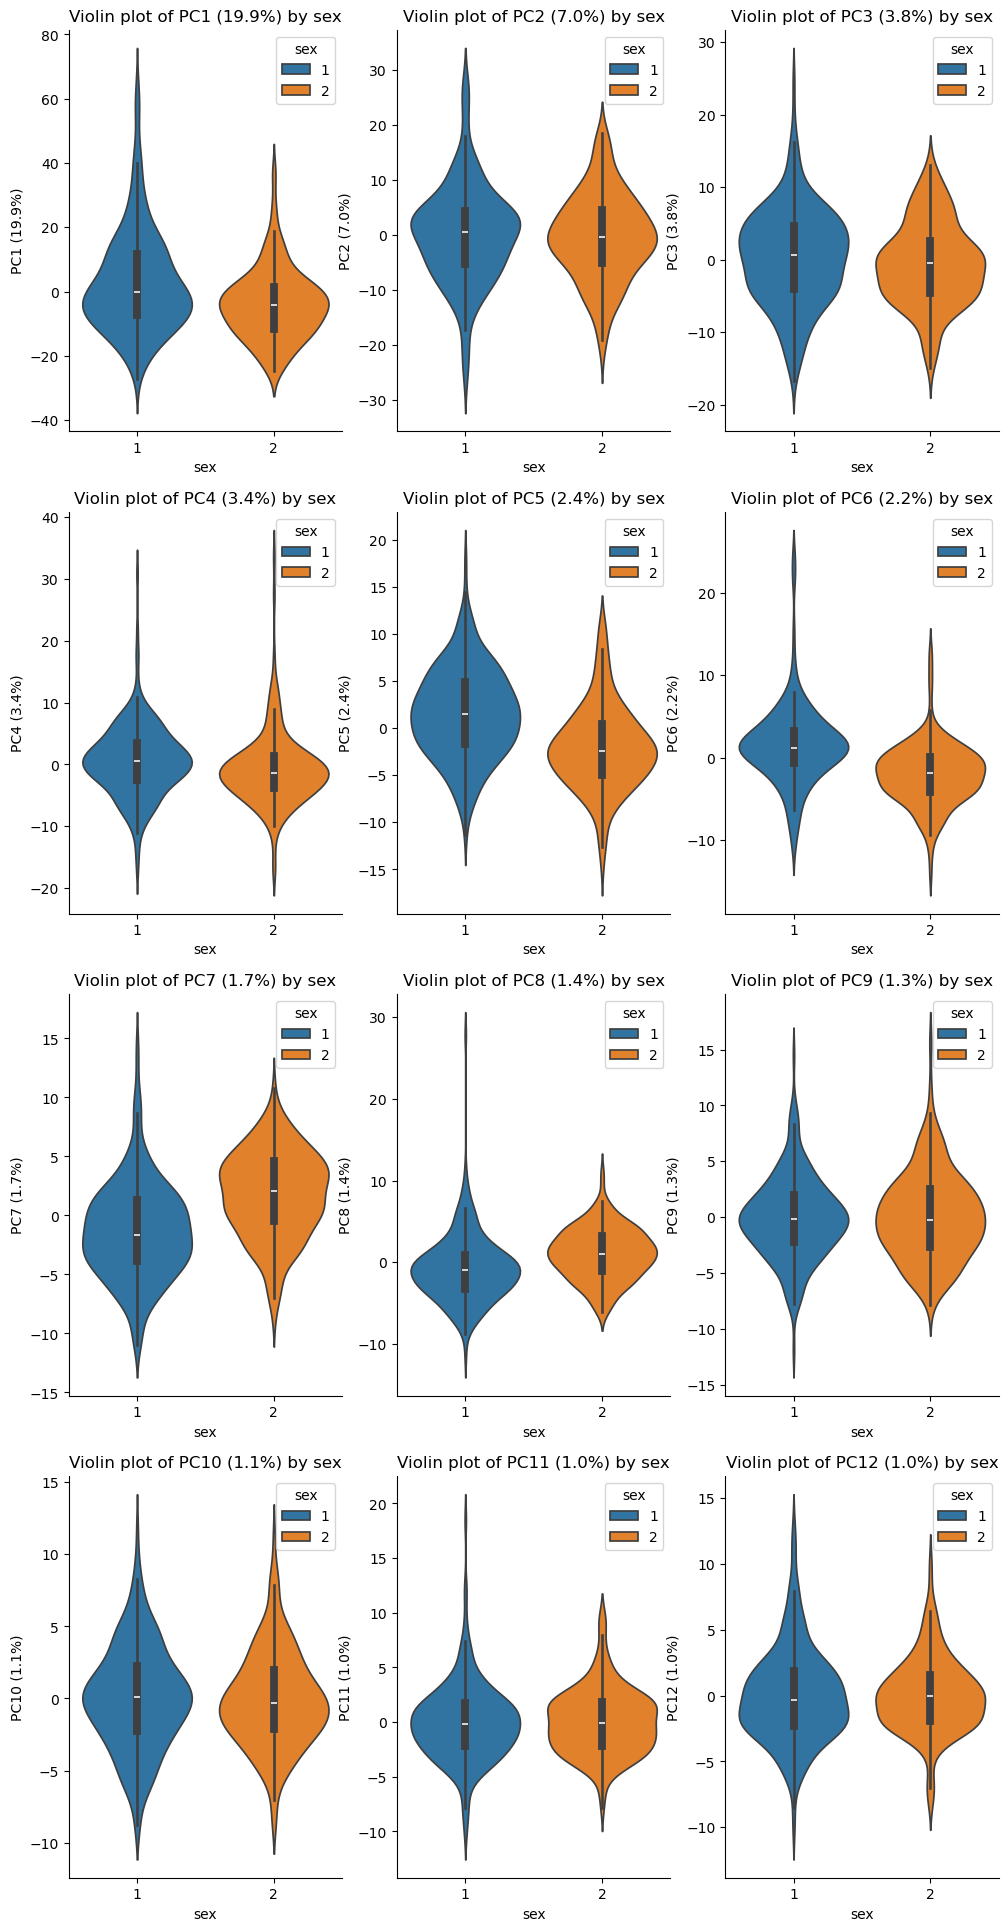

In [14]:
#Visualization: violinplots per feature
classname = 'sex'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.violinplot(data=merged_data, x=classname, y=column, hue=classname,
                  ax = axes[column_index], palette = 'tab10')
    axes[column_index].set_title(f'Violin plot of {column} by {classname}')
sns.despine()
plt.show()

## Groupset2(cancer or not)

<Figure size 400x300 with 0 Axes>

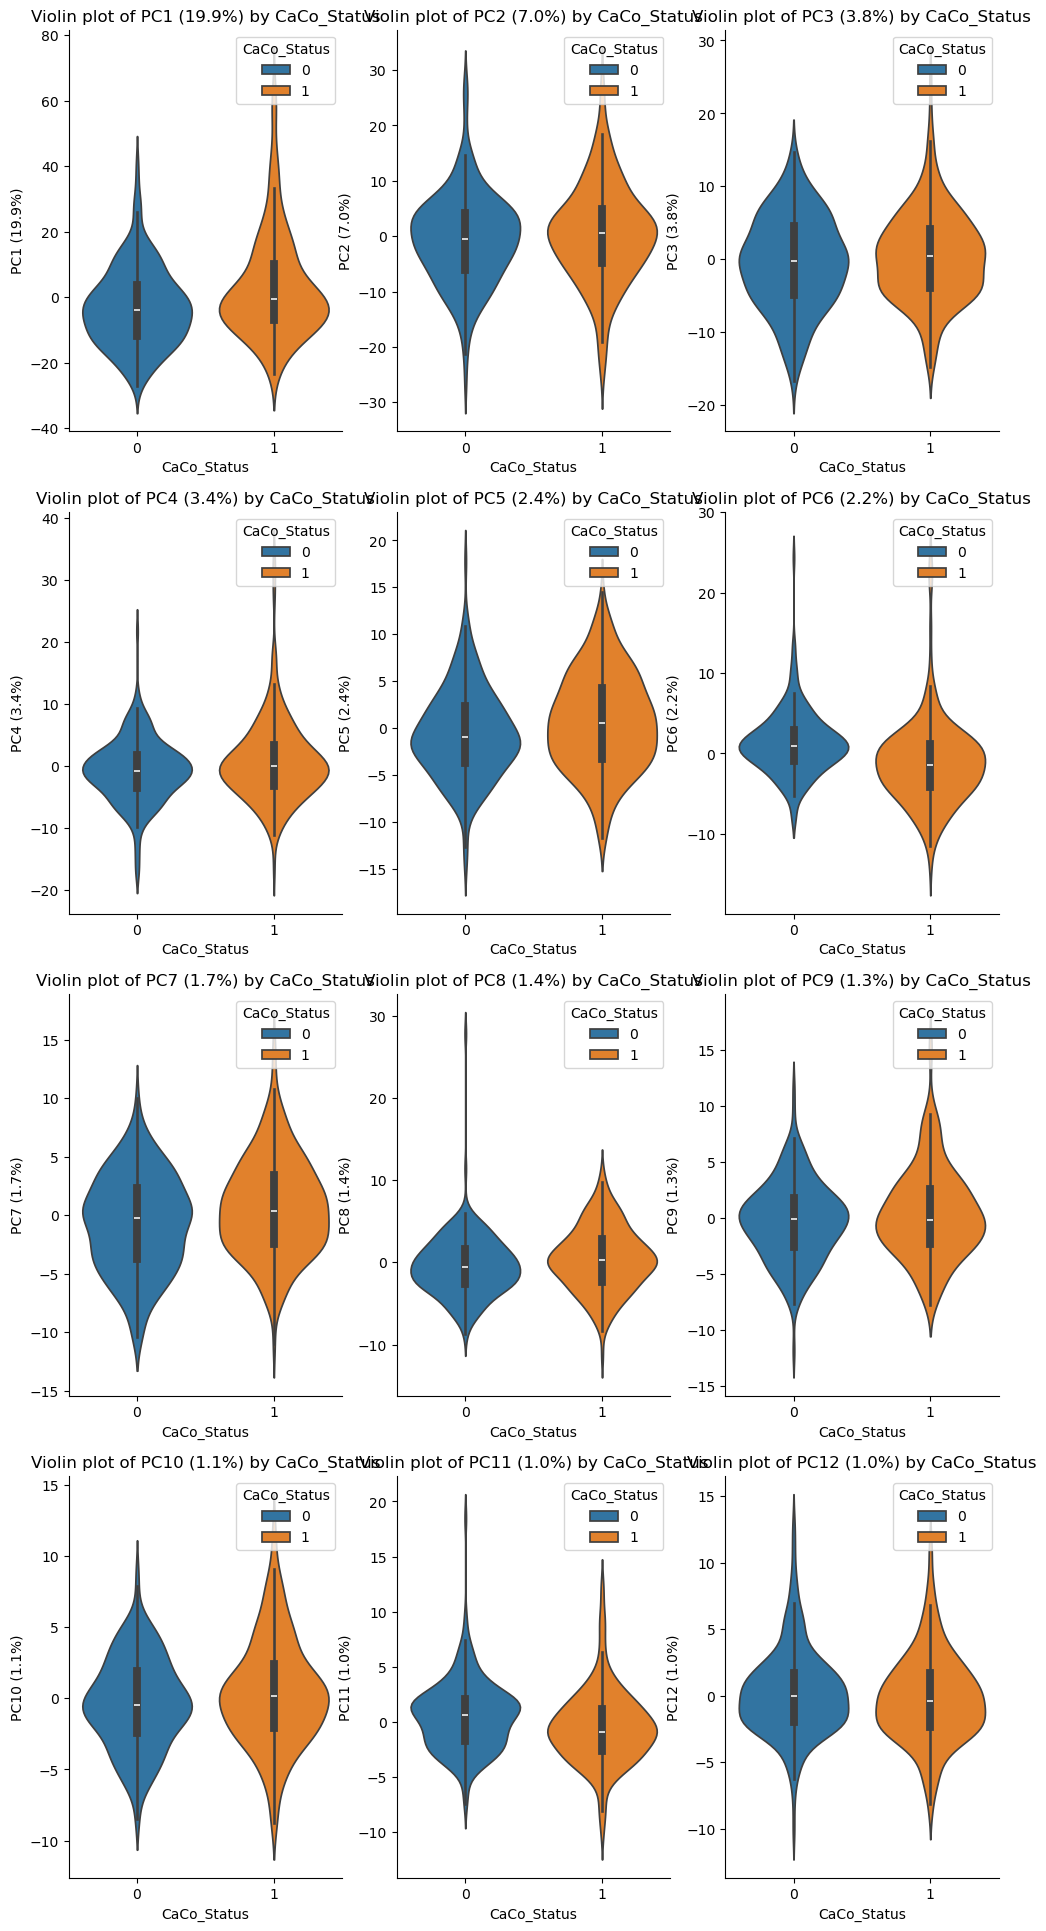

In [15]:
#Visualization: violinplots per feature
classname = 'CaCo_Status'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.violinplot(data=merged_data, x=classname, y=column, hue=classname,
                  ax = axes[column_index], palette = 'tab10')
    axes[column_index].set_title(f'Violin plot of {column} by {classname}')
sns.despine()
plt.show()

## Age

<Figure size 400x300 with 0 Axes>

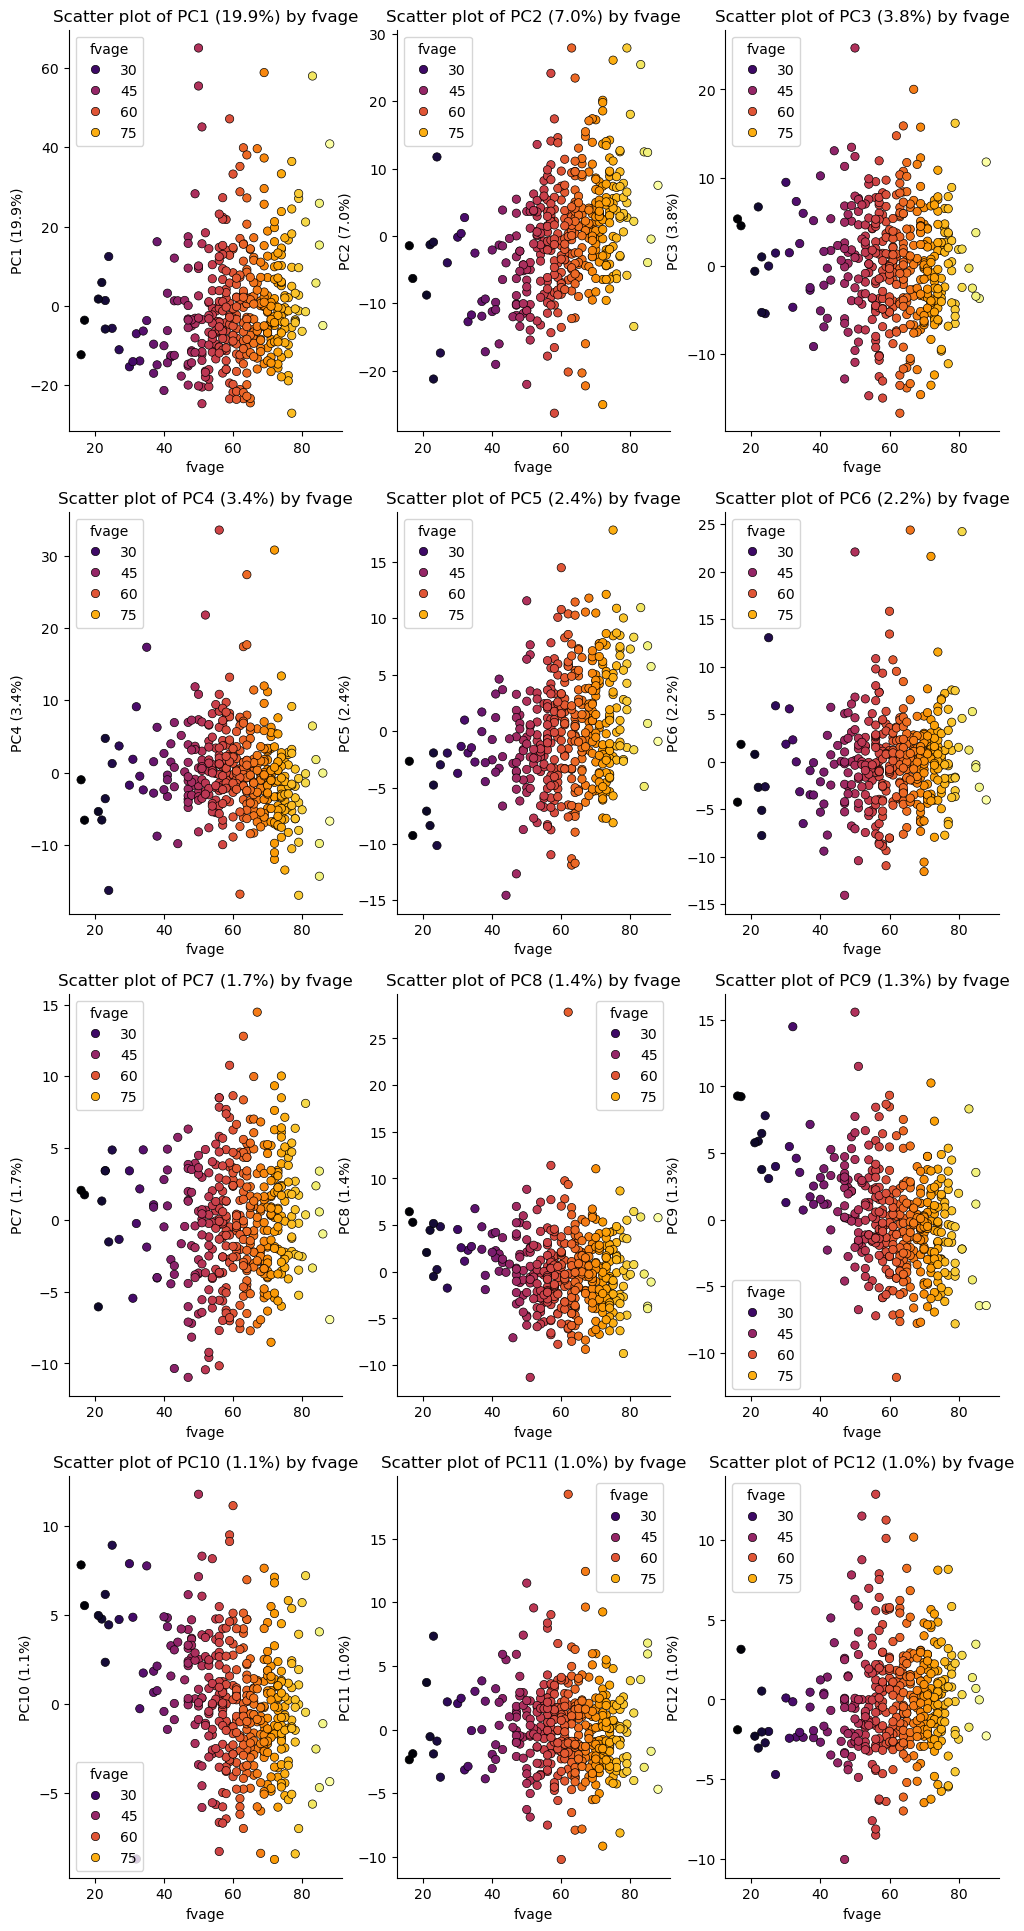

In [16]:
#Visualization: violinplots per feature
classname = 'fvage'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.scatterplot(data = merged_data, x = classname, y = column, hue = classname,
                   ax = axes[column_index], palette = 'inferno', edgecolor = 'black')
    axes[column_index].set_title(f'Scatter plot of {column} by {classname}')
sns.despine()
plt.show()

## BMI

<Figure size 400x300 with 0 Axes>

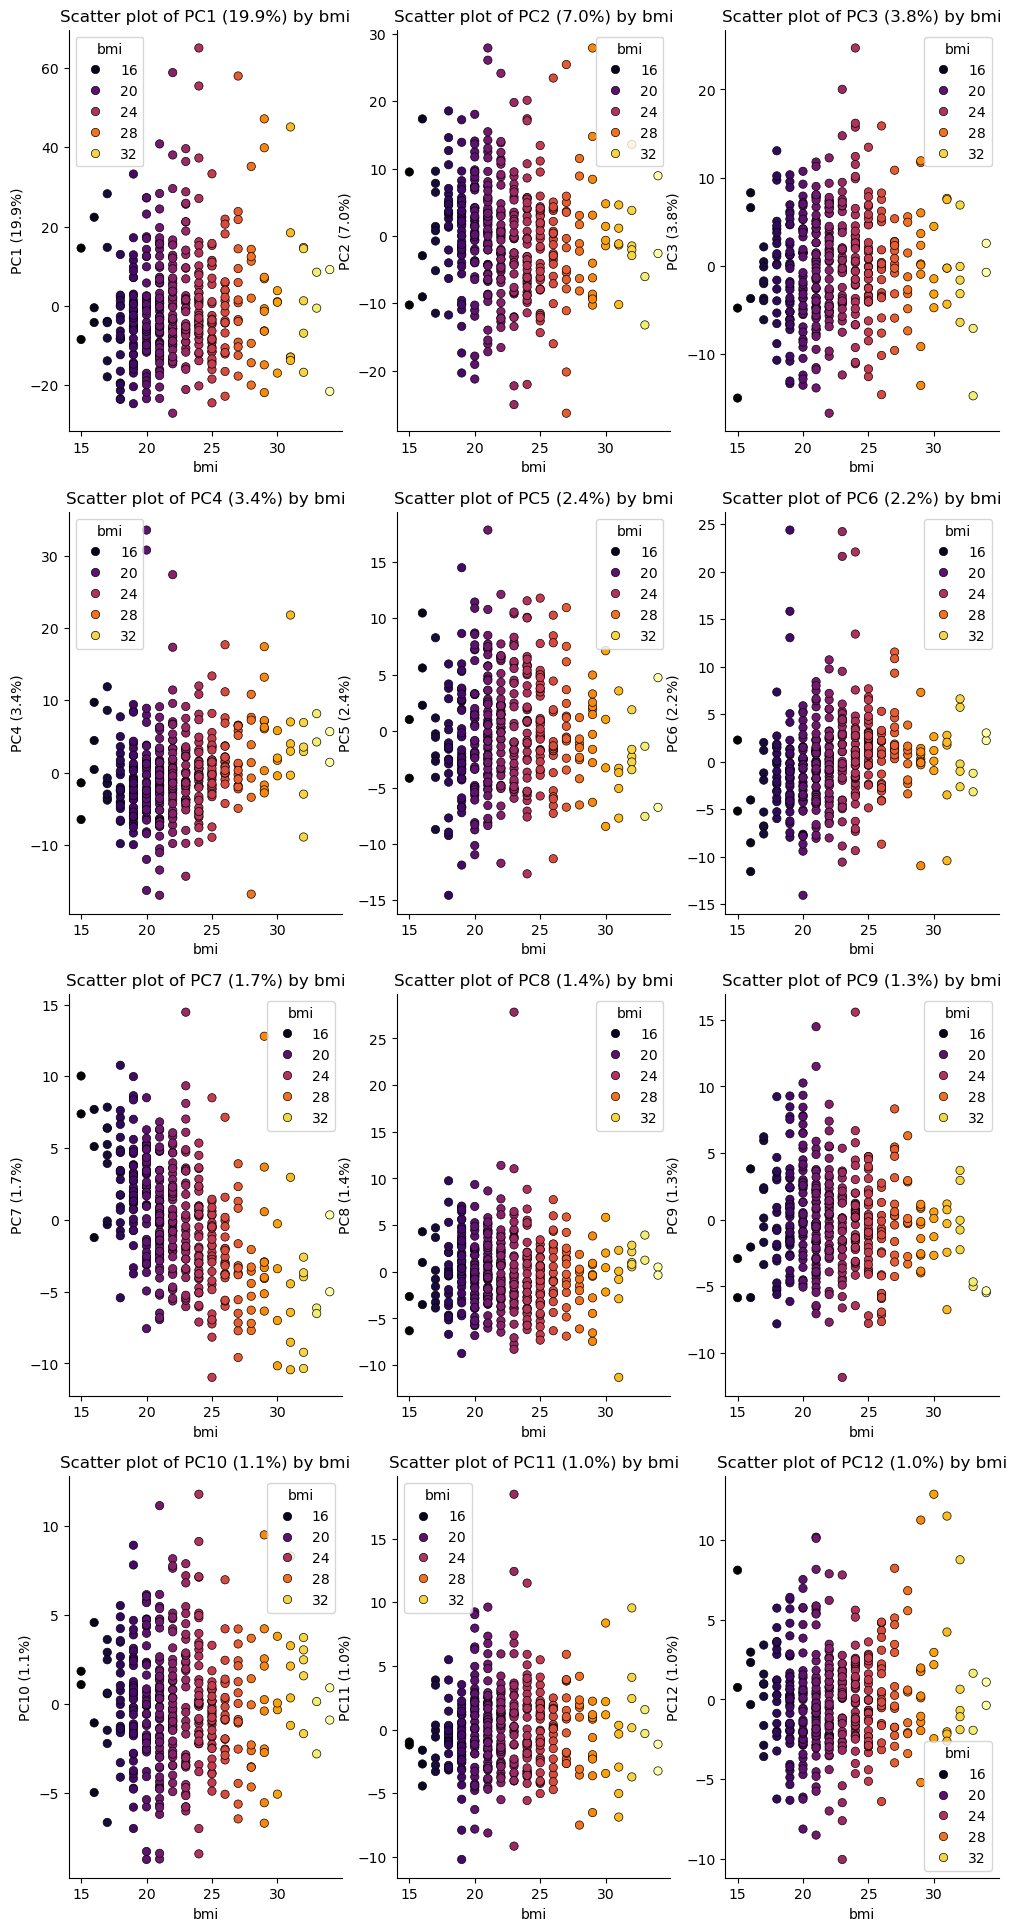

In [17]:
#Visualization: violinplots per feature
classname = 'bmi'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.scatterplot(data = merged_data, x = classname, y = column, hue = classname,
                   ax = axes[column_index], palette = 'inferno', edgecolor = 'black')
    axes[column_index].set_title(f'Scatter plot of {column} by {classname}')
sns.despine()
plt.show()

## Daily alcohol intake

<Figure size 400x300 with 0 Axes>

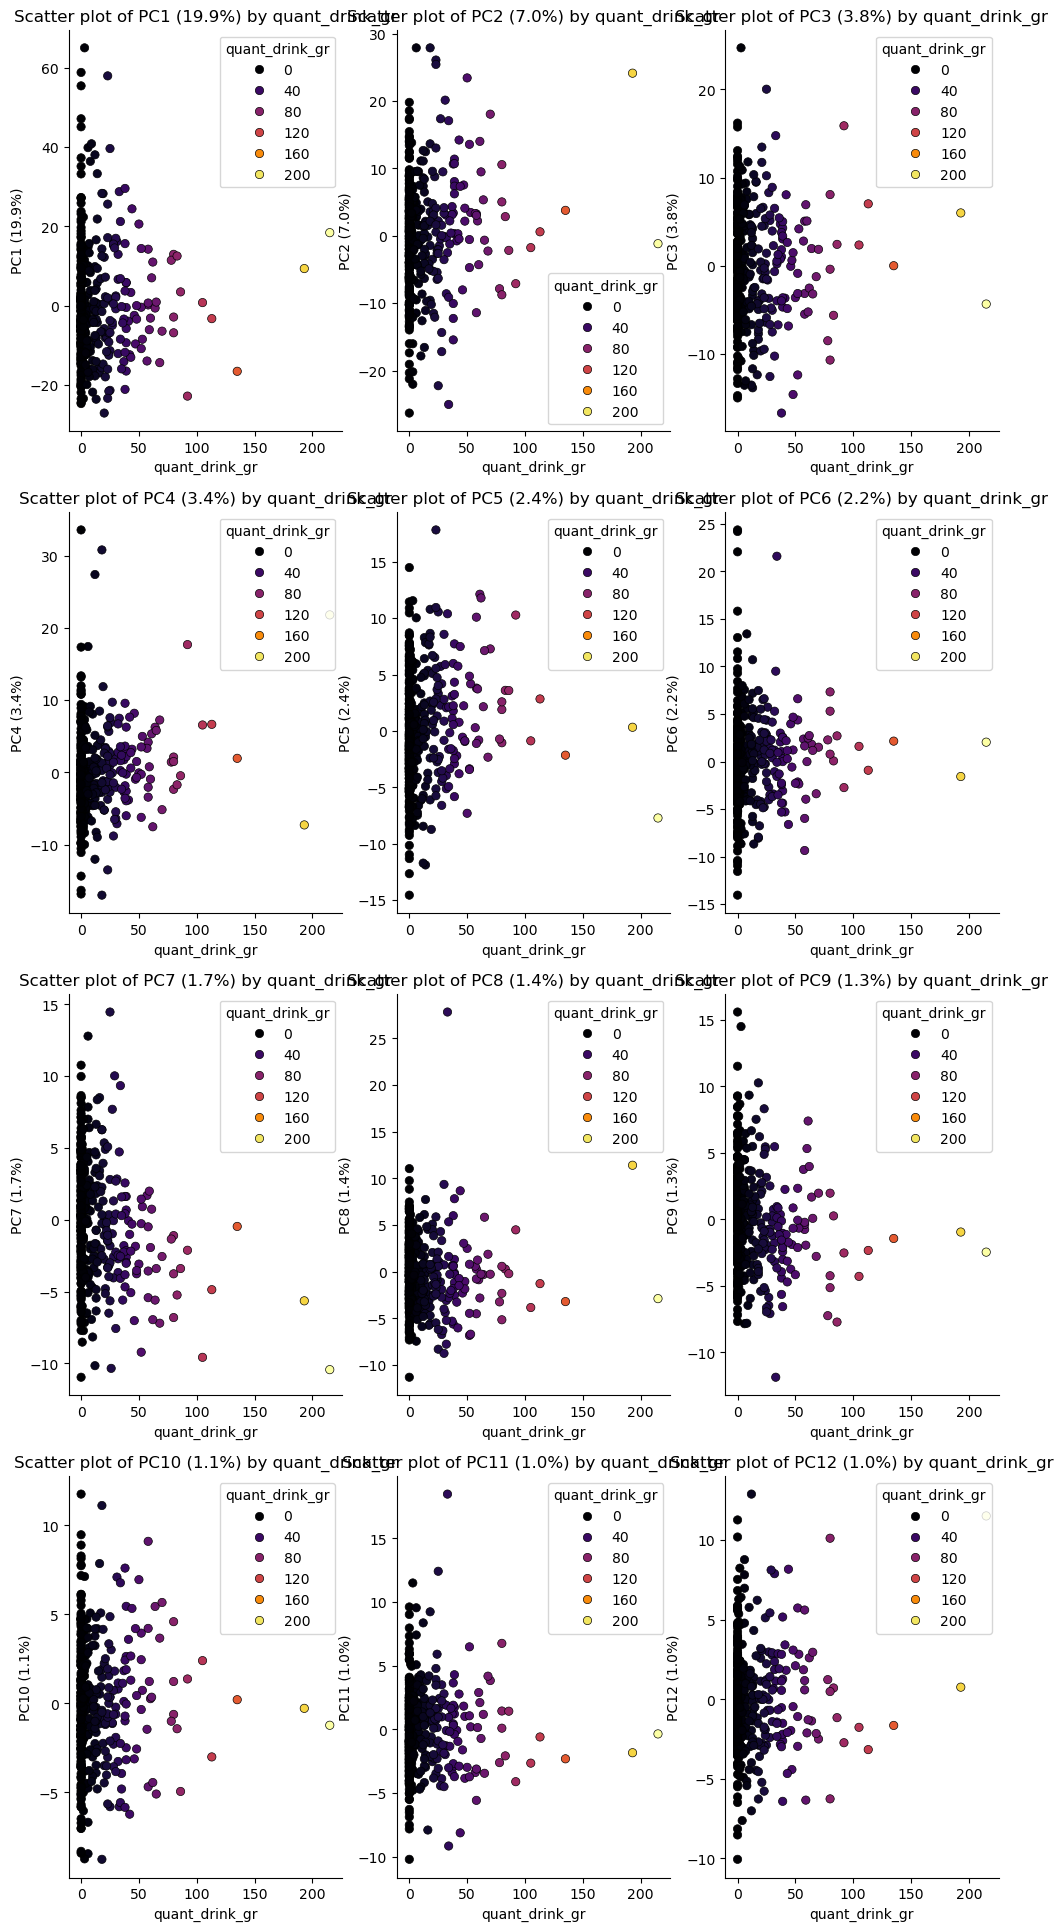

In [18]:
#Visualization: violinplots per feature
classname = 'quant_drink_gr'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.scatterplot(data = merged_data, x = classname, y = column, hue = classname,
                   ax = axes[column_index], palette = 'inferno', edgecolor = 'black')
    axes[column_index].set_title(f'Scatter plot of {column} by {classname}')
sns.despine()
plt.show()

## History of diabetes

<Figure size 400x300 with 0 Axes>

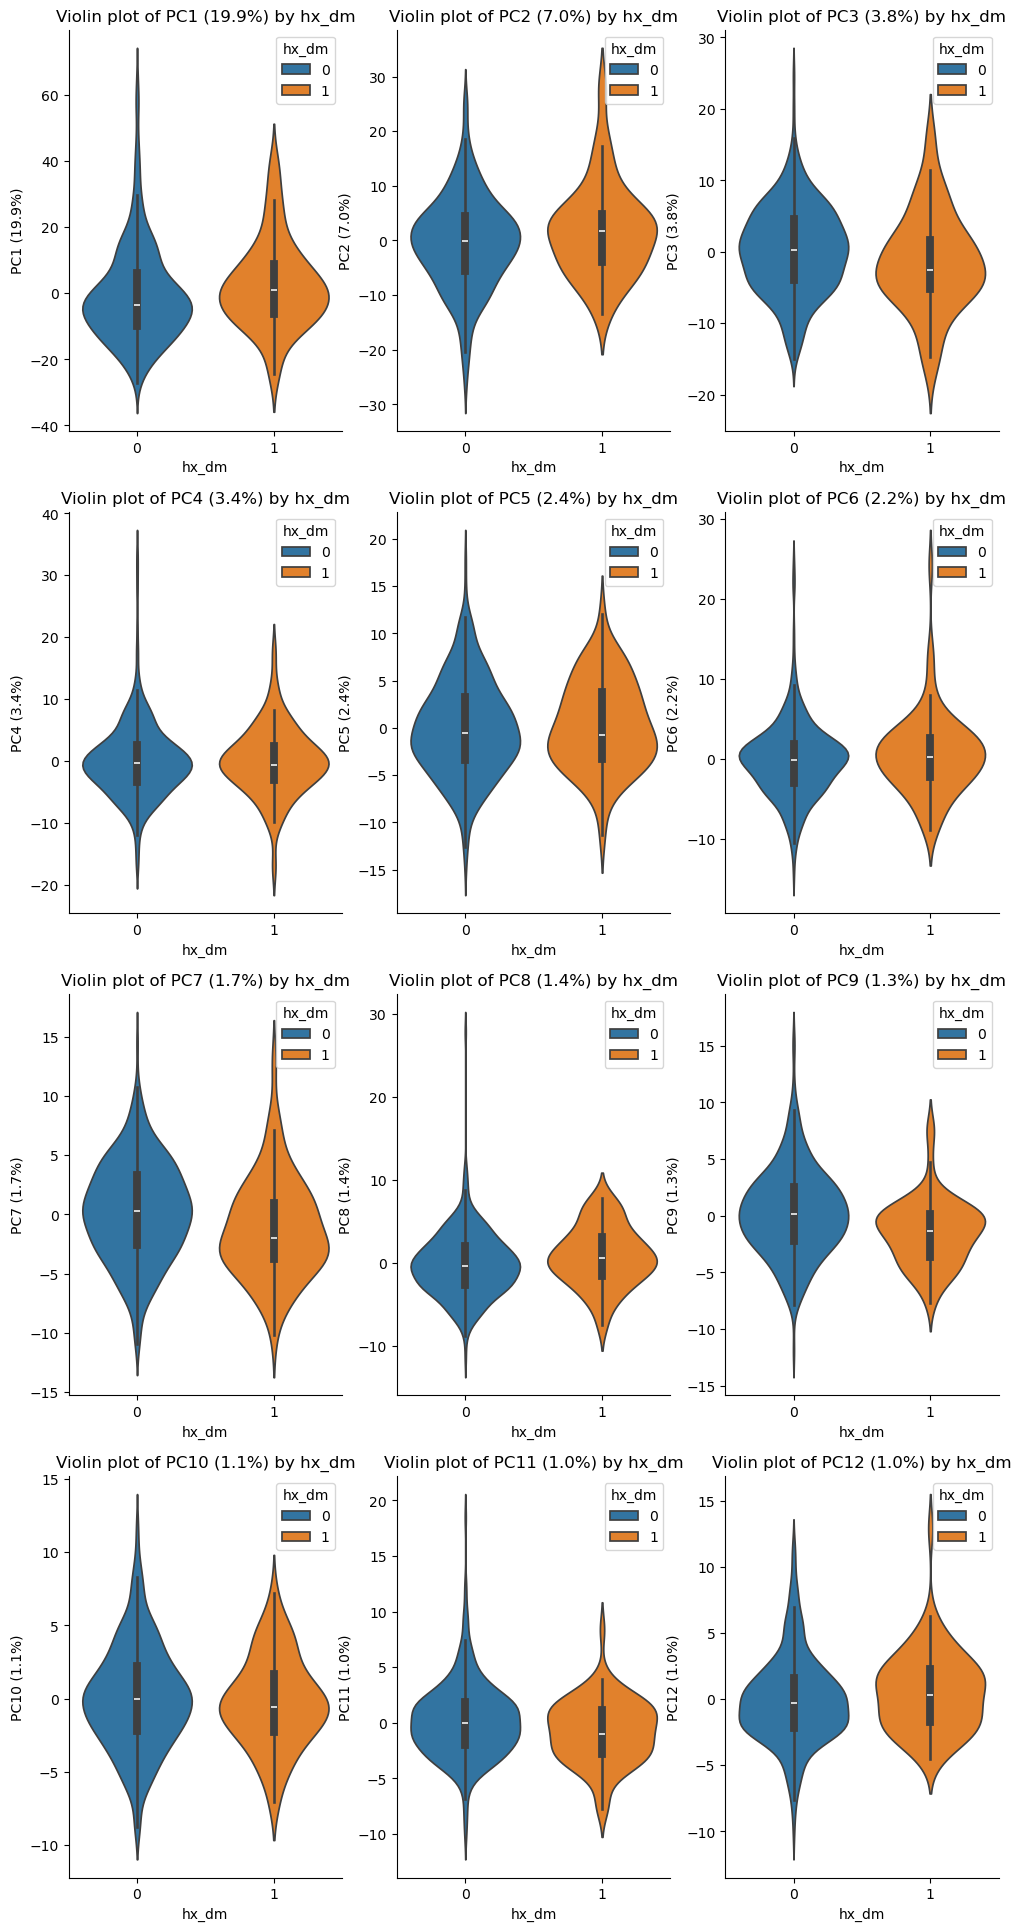

In [19]:
#Visualization: violinplots per feature

classname = 'hx_dm'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.violinplot(data=merged_data, x=classname, y=column, hue=classname,
                  ax = axes[column_index], palette = 'tab10')
    axes[column_index].set_title(f'Violin plot of {column} by {classname}')
sns.despine()
plt.show()

## Pack years(smoking)

<Figure size 400x300 with 0 Axes>

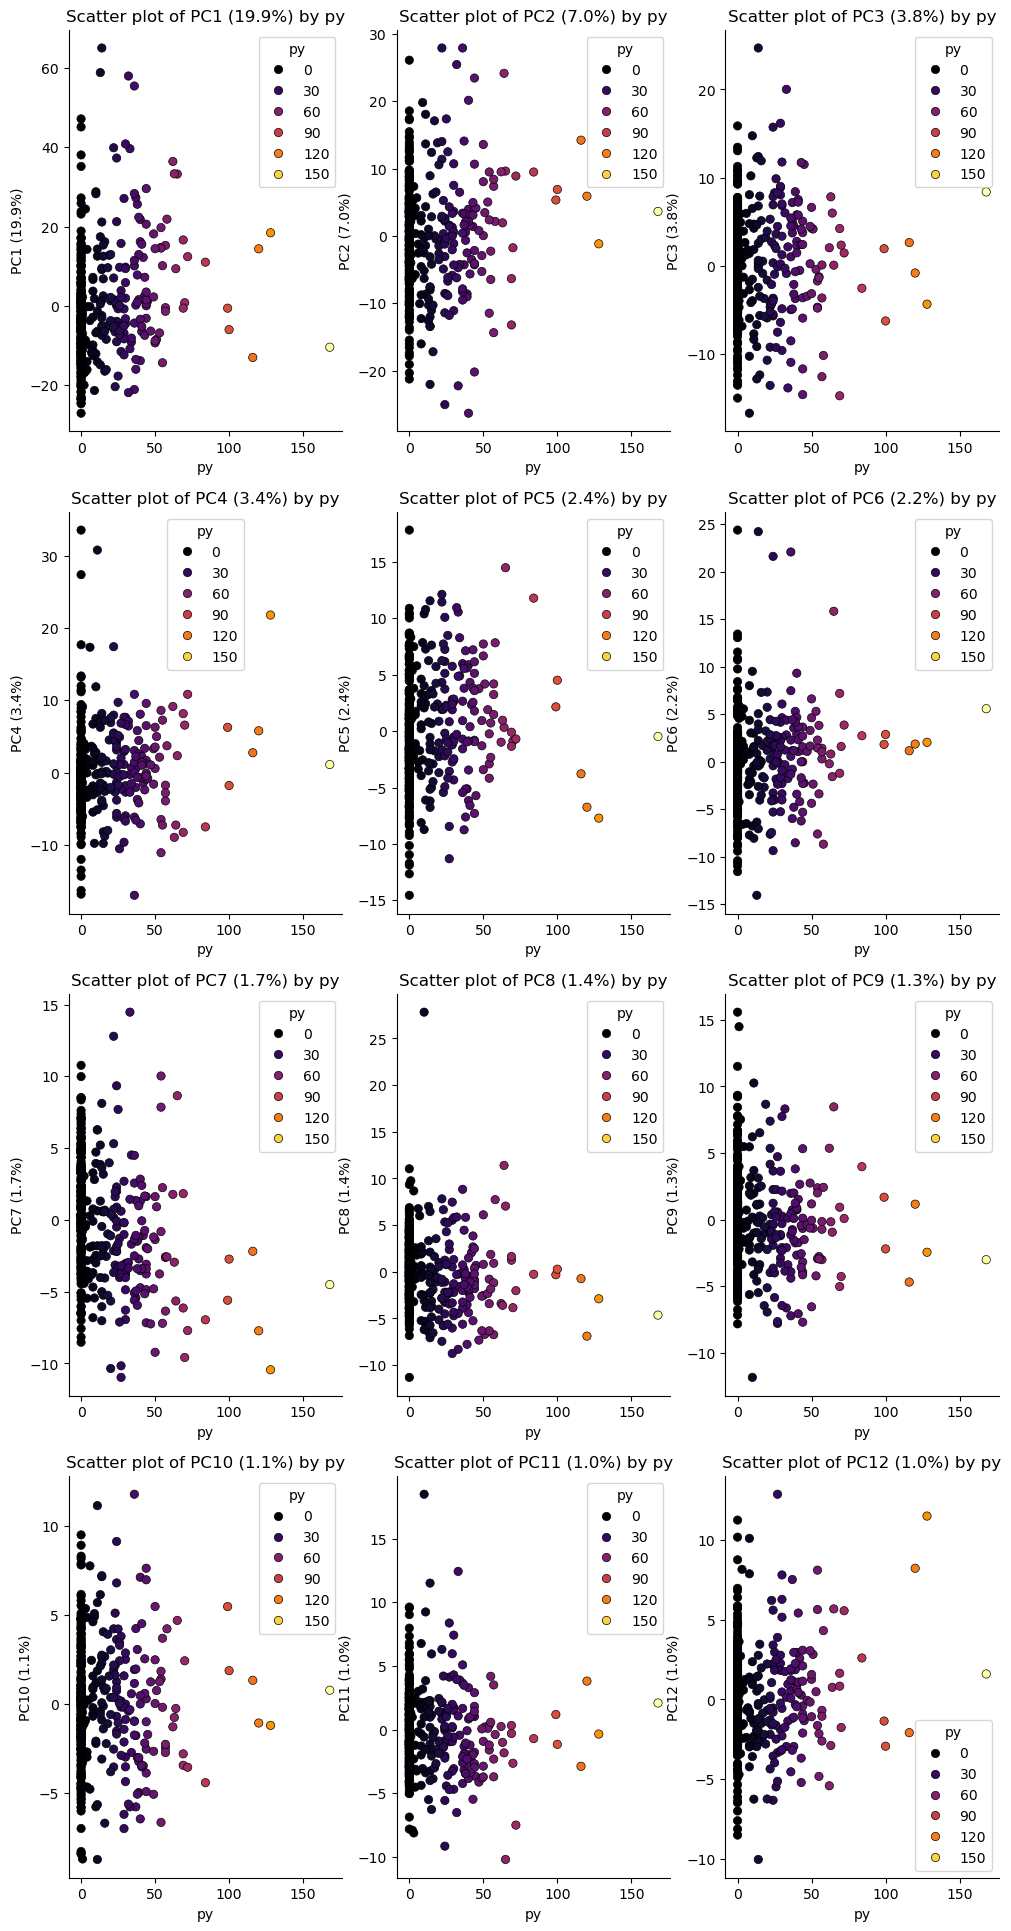

In [20]:
#Visualization: violinplots per feature
classname = 'py'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 3
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.scatterplot(data = merged_data, x = classname, y = column, hue = classname,
                   ax = axes[column_index], palette = 'inferno', edgecolor = 'black')
    axes[column_index].set_title(f'Scatter plot of {column} by {classname}')
sns.despine()
plt.show()

## Progress of cancer

<Figure size 400x300 with 0 Axes>

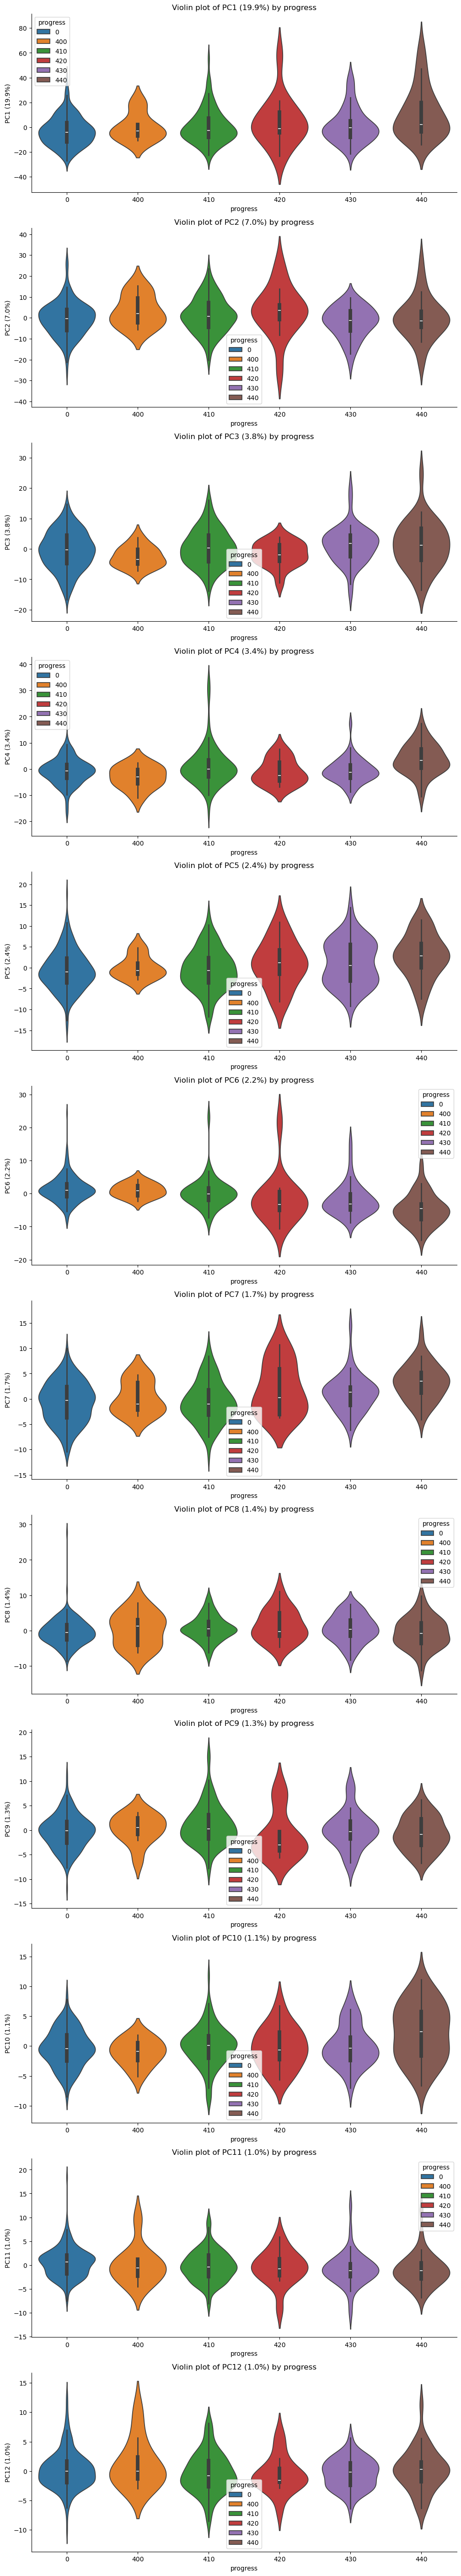

In [21]:
#Visualization: violinplots per feature

classname = 'progress'

plt.figure(figsize=(4, 3))
columns_plot = [col for col in merged_data.columns[:12]]

n_cols = 1
n_rows = (len(columns_plot) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize = (12, 6*n_rows))
axes = axes.flatten()

for column_index, column in enumerate(columns_plot):
    if column == classname:
        continue
    # plt.subplot(10, 10, column_index+1)
    sns.violinplot(data=merged_data, x=classname, y=column, hue=classname,
                  ax = axes[column_index], palette = 'tab10')
    axes[column_index].set_title(f'Violin plot of {column} by {classname}')
sns.despine()
plt.show()

# Save data

In [22]:
tempDF = pcaDF_proj

fileDir = './Data/'
fileName = 'DataForRegression.csv'
tempDF.to_csv(fileDir + fileName, index = True)